# Decoder-specific DEM prior calibration

This walkthrough fits known-support covariance priors and trains separate effective priors for MWPM and ldpc Union-find. Detector supports and logical actions stay fixed. Training uses observed detection events and logical outcomes. Independent validation shots select checkpoints, and a shared held-out test set measures the probability of an unsuccessful complete memory shot.

Install the project and its optional extras in the notebook kernel environment with `python -m pip install -e '.[decoder-training,notebook]'`. The YAML files use the pinned THeatA checkout in `vendor/theata`. Select the smoke YAML for a short run or the research YAML for a larger experiment.

In [1]:
# EDITABLE PARAMETERS
# Replace None with a value to override the selected YAML or package default.
from dataclasses import asdict, replace
from pathlib import Path

from theata_prior.decoder_training.config import config_from_dict, load_training_config
from theata_prior.decoder_training.experiment import build, evaluate, fit, preflight, sample, train
from theata_prior.decoder_training.plotting import PlotOptions, load_results, plot_results

root = Path.cwd()
if not (root / "pyproject.toml").exists():
    root = root.parent
config_path = root / "configs/decoder_training_research.yaml"
output = root / "results/decoder_training_research_mwpm"
resume = True
stages = ("build", "sample", "fit", "train", "evaluate", "plot")
timing_probe_shots = 128  # Set to zero to skip. Runs after sampling.

# Choose ("uf",), ("mwpm",), or ("mwpm", "uf"). None uses the YAML setting.
target_decoders = ("mwpm",)     # CEM training targets.
evaluation_decoders = ("mwpm",)  # Decoders used for held-out evaluation.
plot_decoders = ("mwpm",)        # Evaluation panels and trained priors to show.

physical = dict(
    theata_path=None, hardware=None, distances=None, basis=None, physical_error_rates=None,
    sample_source=None, training_shots=None, test_shots=None, repetitions=None, seed=None,
    sample_chunk_shots=None, decode_chunk_shots=None, covariance_chunk_shots=None,
    covariance_block_detectors=None, probability_floor=None, probability_ceiling=None,
    strict_estimation=None,
)
experiment = dict(
    rounds_by_distance=None, validation_shots=None, optimizer_seeds=None, initializations=None,
    covariance_failure=None, uniform_probability=None, p_min=None, p_max=None,
    grouping=None, manual_groups=None, target_decoders=target_decoders,
    evaluation_decoders=evaluation_decoders, plot_decoders=plot_decoders,
    ldpc_version=None, uf_mode=None, bits_per_step=None,
)
cem = dict(
    population_size=None, elite_count=None, generations=None, initial_std=None, smoothing=None,
    min_std=None, theta_bounds=None, train_batch_shots=None, validation_interval=None,
)
use_full_training_prefix = False  # True sets train_batch_shots to null.
resources = dict(
    total_workers=None, case_jobs=None, candidate_jobs=None, sampling_jobs=None,
    covariance_jobs=None, native_threads=None,
)
plots = PlotOptions(
    distance=None, physical_error_rate=None, calibration_shots=None, replicate=None,
    optimizer_seed=None, initialization=None, color_normalization="linear", formats=("png", "pdf"),
)

## Validate settings and estimate resource use

Preflight can count the sector detectors from the ideal circuit. It reports the exact mechanism and group counts after the physical models are built.

`target_decoders` selects which priors CEM trains. `evaluation_decoders` selects which decoders score the held-out shots. Use a fresh output directory when changing either selection for a new run.

In [2]:
from IPython.display import Image, Markdown, display
from theata_prior.io import read_json

settings = asdict(load_training_config(config_path))
for section, overrides in (("physical", physical), ("cem", cem), ("resources", resources)):
    settings[section].update({key: value for key, value in overrides.items() if value is not None})
settings.update({key: value for key, value in experiment.items() if value is not None})
if use_full_training_prefix:
    settings["cem"]["train_batch_shots"] = None
config = config_from_dict(settings, config_path)
plot_options = replace(plots, decoders=config.plot_decoders)
if not resume and any(stage != "plot" for stage in stages) and (output / "decoder_training.json").exists():
    raise FileExistsError(f"Choose a fresh output directory or enable resume: {output}")

def table(rows, columns):
    def display_value(value):
        if isinstance(value, float):
            return f"{value:.4g}"
        return "—" if value is None else str(value)
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines += ["| " + " | ".join(display_value(row.get(column)) for column in columns) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

if any(stage != "plot" for stage in stages):
    display(preflight(config, output))

[{'distance': 5,
  'rounds': 5,
  'physical_error_rate': 0.001,
  'detectors': 72,
  'mechanisms': None,
  'groups': None,
  'free_parameters': None,
  'sample_disk_bytes_estimate': 18250000,
  'covariance_working_bytes_estimate': 1345536,
  'candidate_batch_bytes_per_worker_estimate': 299008,
  'optimization_conditions': 3,
  'decoder_shot_budget_upper': 3801840,
  'heldout_decoder_shot_budget_upper': 1200000},
 {'distance': 5,
  'rounds': 5,
  'physical_error_rate': 0.002,
  'detectors': 72,
  'mechanisms': None,
  'groups': None,
  'free_parameters': None,
  'sample_disk_bytes_estimate': 18250000,
  'covariance_working_bytes_estimate': 1345536,
  'candidate_batch_bytes_per_worker_estimate': 299008,
  'optimization_conditions': 3,
  'decoder_shot_budget_upper': 3801840,
  'heldout_decoder_shot_budget_upper': 1200000},
 {'distance': 7,
  'rounds': 7,
  'physical_error_rate': 0.001,
  'detectors': 192,
  'mechanisms': None,
  'groups': None,
  'free_parameters': None,
  'sample_disk_by

## Build the physical models and sample independent streams

Training budgets use nested prefixes of the same training pool. Validation shots are additional to the calibration budget. All methods in a physical case use the same test samples.

In [3]:
if "build" in stages:
    built = build(config, output)
    display(preflight(config, output))
if "sample" in stages:
    sample(config, output)
    if timing_probe_shots:
        display(preflight(config, output, probe_shots=timing_probe_shots))

build: d=5 compiling THeatA model


build: d=5 p=0.001; 72 detectors, 301 identifiable edges
build: d=5 p=0.002; 72 detectors, 301 identifiable edges
build: d=7 compiling THeatA model
build: d=7 p=0.001; 192 detectors, 883 identifiable edges
build: d=7 p=0.002; 192 detectors, 883 identifiable edges


[{'distance': 5,
  'rounds': 5,
  'physical_error_rate': 0.001,
  'detectors': 72,
  'mechanisms': 301,
  'groups': 15,
  'free_parameters': 14,
  'sample_disk_bytes_estimate': 18250000,
  'covariance_working_bytes_estimate': 1345536,
  'candidate_batch_bytes_per_worker_estimate': 299008,
  'optimization_conditions': 3,
  'decoder_shot_budget_upper': 3801840,
  'heldout_decoder_shot_budget_upper': 1200000},
 {'distance': 5,
  'rounds': 5,
  'physical_error_rate': 0.002,
  'detectors': 72,
  'mechanisms': 301,
  'groups': 15,
  'free_parameters': 14,
  'sample_disk_bytes_estimate': 18250000,
  'covariance_working_bytes_estimate': 1345536,
  'candidate_batch_bytes_per_worker_estimate': 299008,
  'optimization_conditions': 3,
  'decoder_shot_budget_upper': 3801840,
  'heldout_decoder_shot_budget_upper': 1200000},
 {'distance': 7,
  'rounds': 7,
  'physical_error_rate': 0.001,
  'detectors': 192,
  'mechanisms': 883,
  'groups': 15,
  'free_parameters': 14,
  'sample_disk_bytes_estimate': 

sample: d=5 p=0.001; train, validation, and test ready
sample: d=5 p=0.002; train, validation, and test ready
sample: d=7 p=0.001; train, validation, and test ready
sample: d=7 p=0.002; train, validation, and test ready


[{'distance': 5,
  'rounds': 5,
  'physical_error_rate': 0.001,
  'detectors': 72,
  'mechanisms': 301,
  'groups': 15,
  'free_parameters': 14,
  'sample_disk_bytes_estimate': 18250000,
  'covariance_working_bytes_estimate': 1345536,
  'candidate_batch_bytes_per_worker_estimate': 299008,
  'optimization_conditions': 3,
  'decoder_shot_budget_upper': 3801840,
  'heldout_decoder_shot_budget_upper': 1200000,
  'mwpm_timing_probe_shots': 128,
  'mwpm_timing_probe_seconds': 0.006336080999972182,
  'mwpm_serial_training_seconds_estimate': 188.19348585104876},
 {'distance': 5,
  'rounds': 5,
  'physical_error_rate': 0.002,
  'detectors': 72,
  'mechanisms': 301,
  'groups': 15,
  'free_parameters': 14,
  'sample_disk_bytes_estimate': 18250000,
  'covariance_working_bytes_estimate': 1345536,
  'candidate_batch_bytes_per_worker_estimate': 299008,
  'optimization_conditions': 3,
  'decoder_shot_budget_upper': 3801840,
  'heldout_decoder_shot_budget_upper': 1200000,
  'mwpm_timing_probe_shots': 

## Fit covariance baselines and inspect groups

The known-support fit uses only training detections. Its regularized probabilities are kept alongside the signed raw pair estimates, validity mask, and empirical detector covariance. Group features come from verified detector coordinates or the detector target count.

In [4]:
if "fit" in stages:
    fits = fit(config, output)
    table(fits, ("distance", "physical_error_rate", "replicate", "calibration_shots", "status",
                 "raw_finite_pairs", "total_unique_pairs", "raw_negative_pairs"))
if "build" in stages:
    groups = read_json(built[0].directory / "groups.json")
    display(groups["features"])
    table([{"group": label, "mechanisms": size, "reference": index == groups["reference"]}
           for index, (label, size) in enumerate(zip(groups["labels"], groups["sizes"]))],
          ("group", "mechanisms", "reference"))

fit: d=5 p=0.001 N=1000 rep=0; ok, 2556/2556 finite raw pairs
fit: d=5 p=0.001 N=10000 rep=0; ok, 2556/2556 finite raw pairs
fit: d=5 p=0.001 N=100000 rep=0; ok, 2556/2556 finite raw pairs
fit: d=5 p=0.002 N=1000 rep=0; ok, 2556/2556 finite raw pairs
fit: d=5 p=0.002 N=10000 rep=0; ok, 2556/2556 finite raw pairs
fit: d=5 p=0.002 N=100000 rep=0; ok, 2556/2556 finite raw pairs
fit: d=7 p=0.001 N=1000 rep=0; ok, 18336/18336 finite raw pairs
fit: d=7 p=0.001 N=10000 rep=0; ok, 18336/18336 finite raw pairs
fit: d=7 p=0.001 N=100000 rep=0; ok, 18336/18336 finite raw pairs
fit: d=7 p=0.002 N=1000 rep=0; ok, 18336/18336 finite raw pairs
fit: d=7 p=0.002 N=10000 rep=0; ok, 18336/18336 finite raw pairs
fit: d=7 p=0.002 N=100000 rep=0; ok, 18336/18336 finite raw pairs


| distance | physical_error_rate | replicate | calibration_shots | status | raw_finite_pairs | total_unique_pairs | raw_negative_pairs |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.001 | 0 | 1000 | ok | 2556 | 2556 | 1235 |
| 5 | 0.001 | 0 | 10000 | ok | 2556 | 2556 | 1167 |
| 5 | 0.001 | 0 | 100000 | ok | 2556 | 2556 | 1148 |
| 5 | 0.002 | 0 | 1000 | ok | 2556 | 2556 | 1213 |
| 5 | 0.002 | 0 | 10000 | ok | 2556 | 2556 | 1101 |
| 5 | 0.002 | 0 | 100000 | ok | 2556 | 2556 | 1135 |
| 7 | 0.001 | 0 | 1000 | ok | 18336 | 18336 | 8928 |
| 7 | 0.001 | 0 | 10000 | ok | 18336 | 18336 | 8855 |
| 7 | 0.001 | 0 | 100000 | ok | 18336 | 18336 | 8586 |
| 7 | 0.002 | 0 | 1000 | ok | 18336 | 18336 | 8928 |
| 7 | 0.002 | 0 | 10000 | ok | 18336 | 18336 | 8884 |
| 7 | 0.002 | 0 | 100000 | ok | 18336 | 18336 | 8664 |

'Verified Stim (x, y, round) coordinates. Pair displacement is orientation invariant and classified by spatial axis occupancy and whether time changes. Location uses only observed endpoints: initial if touching first, else final if touching last, otherwise bulk.'

| group | mechanisms | reference |
| --- | --- | --- |
| pair axial, cross round / bulk | 24 | False |
| pair axial, cross round / final | 8 | False |
| pair axial, cross round / initial | 8 | False |
| pair diagonal, cross round / bulk | 45 | False |
| pair diagonal, cross round / final | 15 | False |
| pair diagonal, cross round / initial | 15 | False |
| pair diagonal, same round / bulk | 60 | True |
| pair diagonal, same round / final | 15 | False |
| pair diagonal, same round / initial | 15 | False |
| pair same site, cross round / bulk | 36 | False |
| pair same site, cross round / final | 12 | False |
| pair same site, cross round / initial | 12 | False |
| singleton / bulk | 24 | False |
| singleton / final | 6 | False |
| singleton / initial | 6 | False |

## Train, freeze, and evaluate

CEM adjusts group weights at a fixed mean LLR scale. Its selected priors are effective decoder parameters. The prior error tables measure their separate agreement with the actual canonical mechanism probabilities. A flat training run or an initialization selected by validation is a valid outcome.

In [5]:
if "train" in stages:
    training = train(config, output)
    table(training, ("target_decoder", "status", "optimizer_evaluations", "validation_evaluations",
                     "decoder_shot_evaluations", "distinct_train_shots", "flat_generations"))
if "evaluate" in stages:
    evaluate(config, output)
if (output / "evaluation_complete.json").exists():
    evaluation, prior_errors, artifact_index = load_results(output, decoders=plot_options.decoders)
    table(evaluation[:20], ("method", "evaluation_decoder", "status", "test_shots", "failures",
                            "decoder_failures", "failure_probability", "ci_low", "ci_high"))
    table([row for row in prior_errors if row["comparison"] == "actual" and row["metric"] in
           ("mechanisms", "pair_mechanisms", "singleton_mechanisms")][:20],
          ("method", "metric", "status", "rmse", "mae", "count"))

train: d=5 p=0.001 N=1000 rep=0 covariance seed=0 mwpm


train: d=5 p=0.001 N=10000 rep=0 covariance seed=0 mwpm
train: d=5 p=0.001 N=100000 rep=0 covariance seed=0 mwpm
train: d=5 p=0.002 N=1000 rep=0 covariance seed=0 mwpm
train: d=5 p=0.002 N=10000 rep=0 covariance seed=0 mwpm
train: d=5 p=0.002 N=100000 rep=0 covariance seed=0 mwpm
train: d=7 p=0.001 N=1000 rep=0 covariance seed=0 mwpm
train: d=7 p=0.001 N=10000 rep=0 covariance seed=0 mwpm
train: d=7 p=0.001 N=100000 rep=0 covariance seed=0 mwpm
train: d=7 p=0.002 N=1000 rep=0 covariance seed=0 mwpm
train: d=7 p=0.002 N=10000 rep=0 covariance seed=0 mwpm
train: d=7 p=0.002 N=100000 rep=0 covariance seed=0 mwpm


| target_decoder | status | optimizer_evaluations | validation_evaluations | decoder_shot_evaluations | distinct_train_shots | flat_generations |
| --- | --- | --- | --- | --- | --- | --- |
| mwpm | complete | 534 | 7 | 884000 | 1000 | 0 |
| mwpm | complete | 516 | 7 | 1406768 | 9982 | 0 |
| mwpm | complete | 518 | 7 | 1410864 | 46271 | 0 |
| mwpm | complete | 529 | 7 | 879000 | 1000 | 0 |
| mwpm | complete | 516 | 7 | 1406768 | 9982 | 0 |
| mwpm | complete | 519 | 7 | 1412912 | 46279 | 0 |
| mwpm | complete | 533 | 7 | 883000 | 1000 | 0 |
| mwpm | complete | 525 | 7 | 1425200 | 9989 | 0 |
| mwpm | complete | 527 | 7 | 1429296 | 46198 | 0 |
| mwpm | complete | 539 | 7 | 889000 | 1000 | 0 |
| mwpm | complete | 536 | 7 | 1447728 | 9993 | 0 |
| mwpm | complete | 535 | 7 | 1445680 | 46251 | 0 |

evaluate: d=5 p=0.001; 12 held-out comparisons
evaluate: d=5 p=0.002; 12 held-out comparisons
evaluate: d=7 p=0.001; 12 held-out comparisons
evaluate: d=7 p=0.002; 12 held-out comparisons


| method | evaluation_decoder | status | test_shots | failures | decoder_failures | failure_probability | ci_low | ci_high |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| actual | mwpm | ok | 100000 | 4117 | 0 | 0.04117 | 0.03996 | 0.04242 |
| covariance | mwpm | ok | 100000 | 4746 | 0 | 0.04746 | 0.04616 | 0.0488 |
| initial | mwpm | ok | 100000 | 4746 | 0 | 0.04746 | 0.04616 | 0.0488 |
| cem_mwpm | mwpm | ok | 100000 | 4746 | 0 | 0.04746 | 0.04616 | 0.0488 |
| actual | mwpm | ok | 100000 | 4117 | 0 | 0.04117 | 0.03996 | 0.04242 |
| covariance | mwpm | ok | 100000 | 4192 | 0 | 0.04192 | 0.0407 | 0.04318 |
| initial | mwpm | ok | 100000 | 4192 | 0 | 0.04192 | 0.0407 | 0.04318 |
| cem_mwpm | mwpm | ok | 100000 | 4192 | 0 | 0.04192 | 0.0407 | 0.04318 |
| actual | mwpm | ok | 100000 | 4117 | 0 | 0.04117 | 0.03996 | 0.04242 |
| covariance | mwpm | ok | 100000 | 4117 | 0 | 0.04117 | 0.03996 | 0.04242 |
| initial | mwpm | ok | 100000 | 4117 | 0 | 0.04117 | 0.03996 | 0.04242 |
| cem_mwpm | mwpm | ok | 100000 | 4117 | 0 | 0.04117 | 0.03996 | 0.04242 |
| actual | mwpm | ok | 100000 | 18448 | 0 | 0.1845 | 0.1821 | 0.1869 |
| covariance | mwpm | ok | 100000 | 20401 | 0 | 0.204 | 0.2015 | 0.2065 |
| initial | mwpm | ok | 100000 | 20401 | 0 | 0.204 | 0.2015 | 0.2065 |
| cem_mwpm | mwpm | ok | 100000 | 20401 | 0 | 0.204 | 0.2015 | 0.2065 |
| actual | mwpm | ok | 100000 | 18448 | 0 | 0.1845 | 0.1821 | 0.1869 |
| covariance | mwpm | ok | 100000 | 18595 | 0 | 0.186 | 0.1836 | 0.1884 |
| initial | mwpm | ok | 100000 | 18595 | 0 | 0.186 | 0.1836 | 0.1884 |
| cem_mwpm | mwpm | ok | 100000 | 18595 | 0 | 0.186 | 0.1836 | 0.1884 |

| method | metric | status | rmse | mae | count |
| --- | --- | --- | --- | --- | --- |
| actual | mechanisms | ok | 0 | 0 | 301 |
| actual | pair_mechanisms | ok | 0 | 0 | 265 |
| actual | singleton_mechanisms | ok | 0 | 0 | 36 |
| covariance | mechanisms | ok | 0.005371 | 0.003878 | 301 |
| covariance | pair_mechanisms | ok | 0.004562 | 0.003475 | 265 |
| covariance | singleton_mechanisms | ok | 0.009382 | 0.00685 | 36 |
| initial | mechanisms | ok | 0.005371 | 0.003878 | 301 |
| initial | pair_mechanisms | ok | 0.004562 | 0.003475 | 265 |
| initial | singleton_mechanisms | ok | 0.009382 | 0.00685 | 36 |
| cem_mwpm | mechanisms | ok | 0.005371 | 0.003878 | 301 |
| cem_mwpm | pair_mechanisms | ok | 0.004562 | 0.003475 | 265 |
| cem_mwpm | singleton_mechanisms | ok | 0.009382 | 0.00685 | 36 |
| actual | mechanisms | ok | 0 | 0 | 301 |
| actual | pair_mechanisms | ok | 0 | 0 | 265 |
| actual | singleton_mechanisms | ok | 0 | 0 | 36 |
| covariance | mechanisms | ok | 0.001552 | 0.00118 | 301 |
| covariance | pair_mechanisms | ok | 0.001422 | 0.001125 | 265 |
| covariance | singleton_mechanisms | ok | 0.00229 | 0.00159 | 36 |
| initial | mechanisms | ok | 0.001552 | 0.00118 | 301 |
| initial | pair_mechanisms | ok | 0.001422 | 0.001125 | 265 |

## Plot from saved results

The detailed panels use the selected data replicate and optimizer seed. Sweep figures retain the individual models with fixed-model Wilson intervals. The separate variation table describes spread across replicates and optimizer seeds while retaining the shared test design. Set `stages = ("plot",)` to reload and replot an existing run.

`plot_decoders` selects both the evaluation panels and the corresponding trained-prior curves, heatmaps, and traces. The actual and covariance baselines stay visible. A single-decoder selection writes to `figures/uf` or `figures/mwpm`. A null setting shows all available results.

Generated 20 figures from saved results in /home/quantum_teresheys/workspace/HEM3/theata-prior-calibration/results/decoder_training_research_mwpm/figures/mwpm.

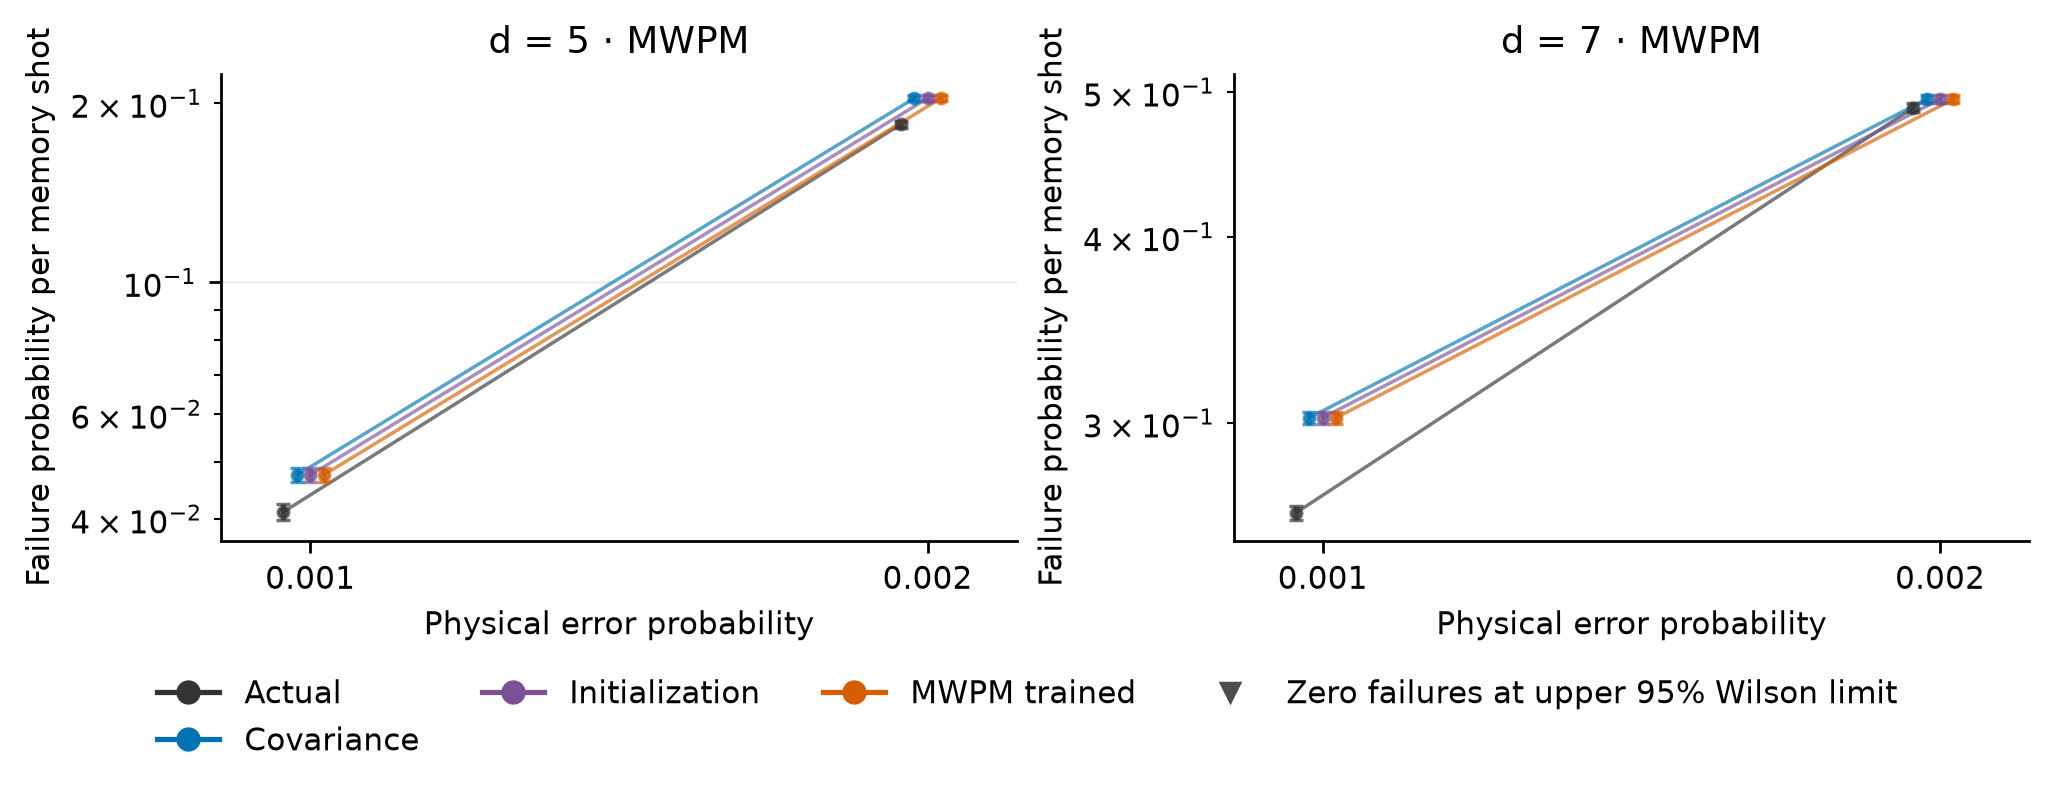

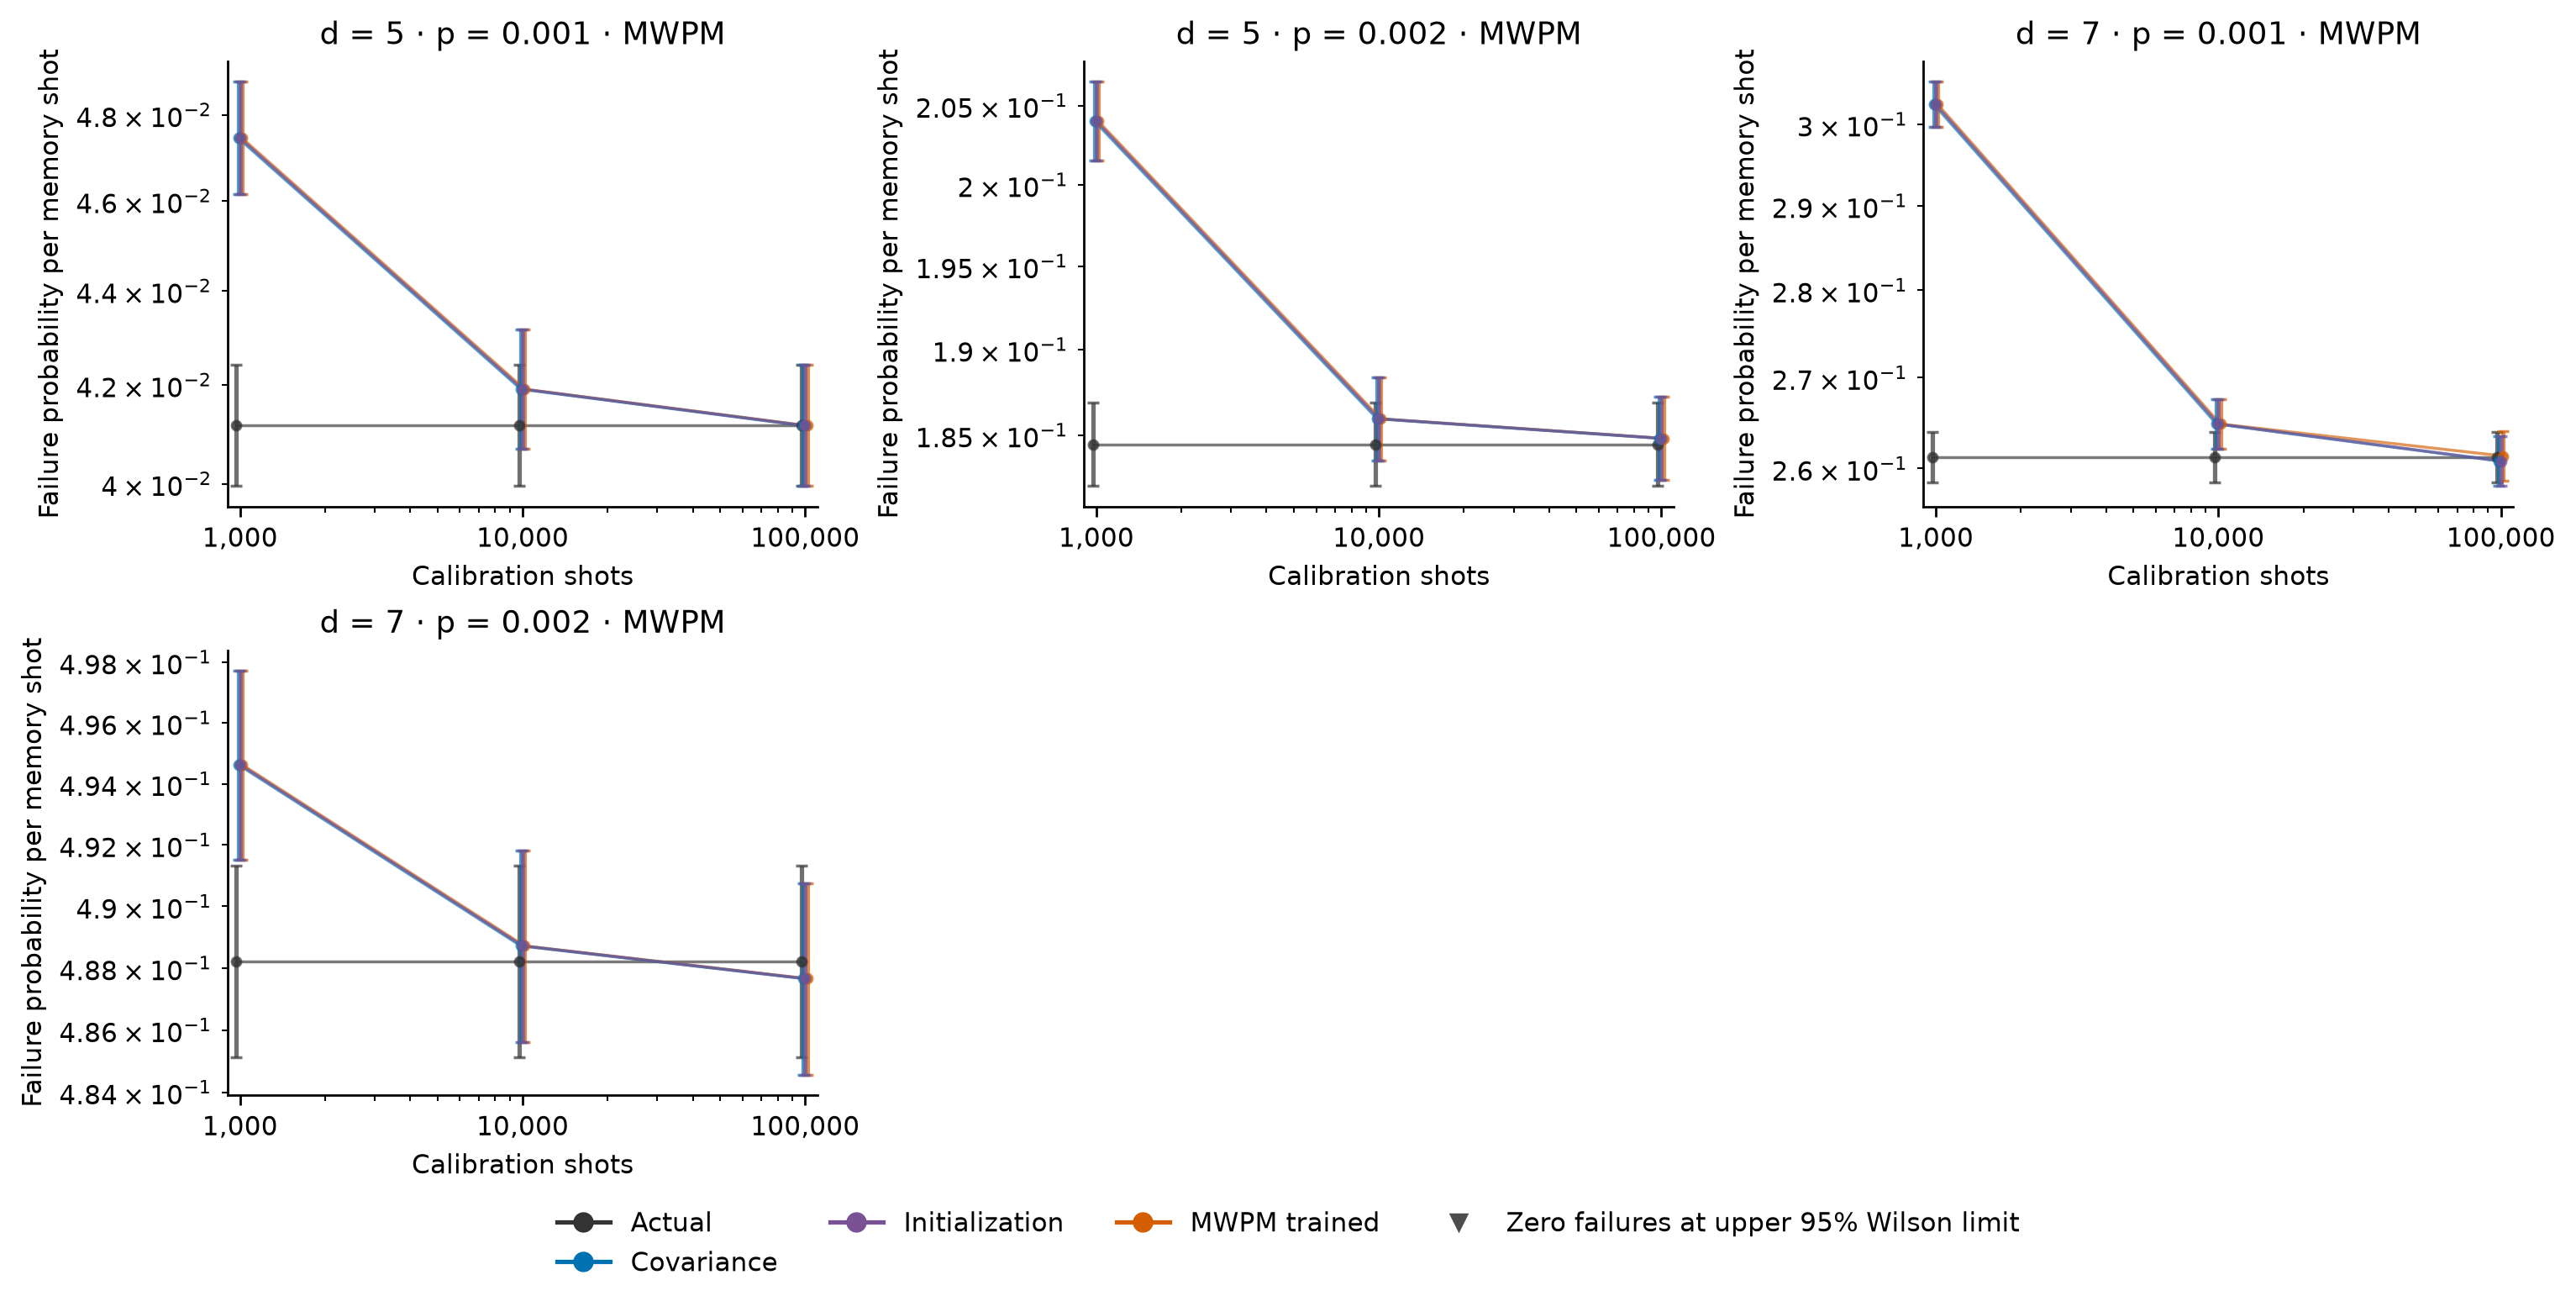

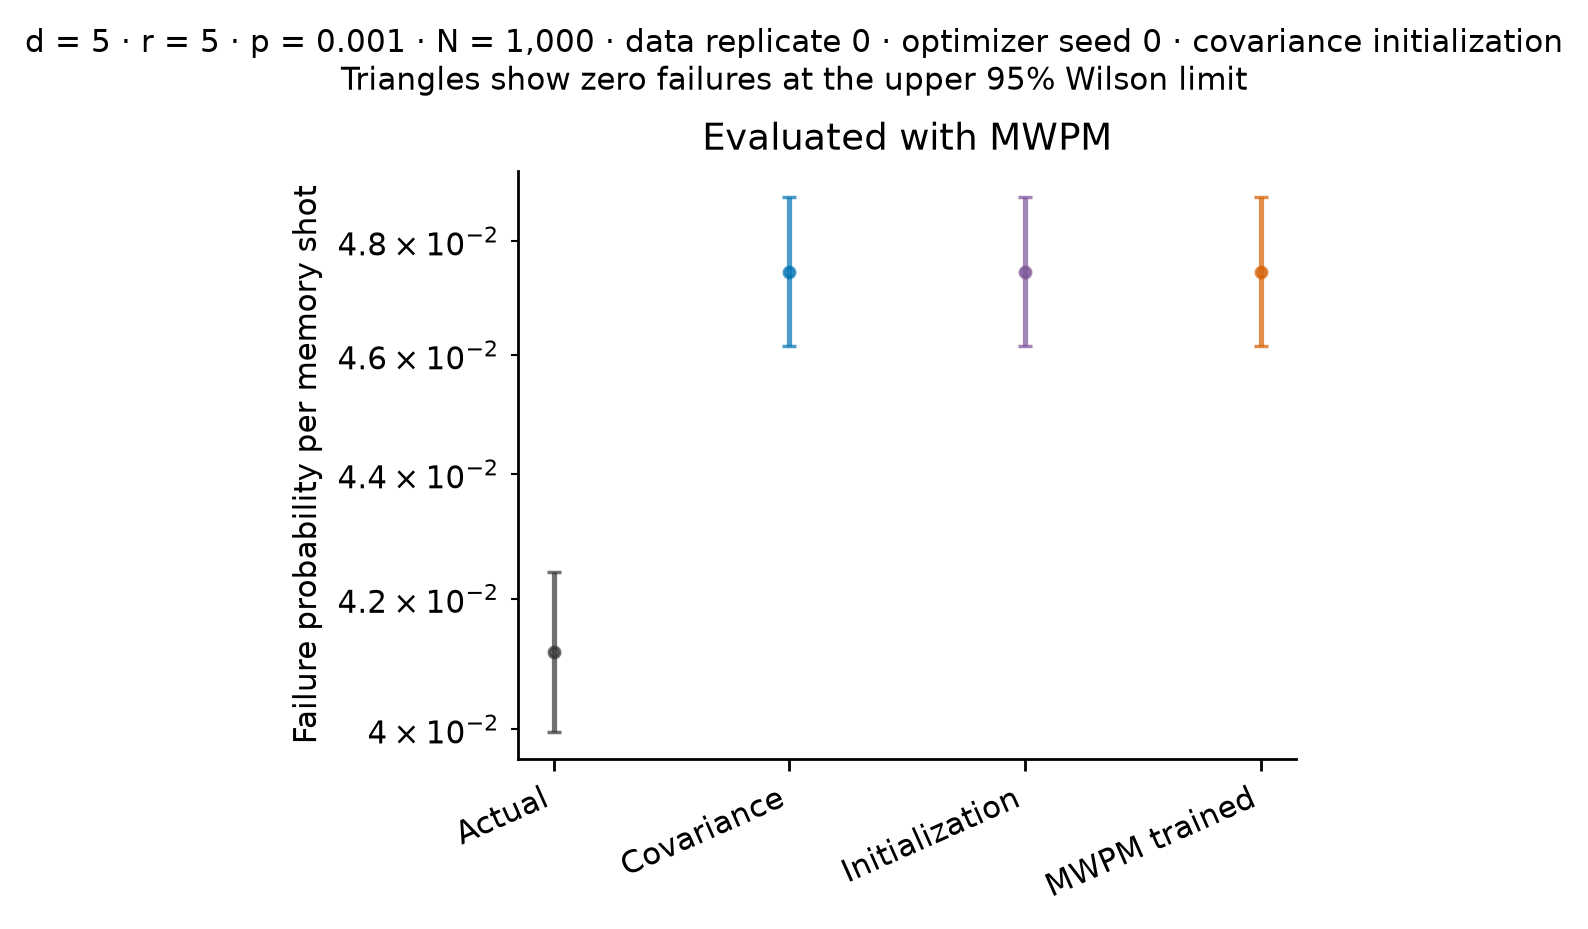

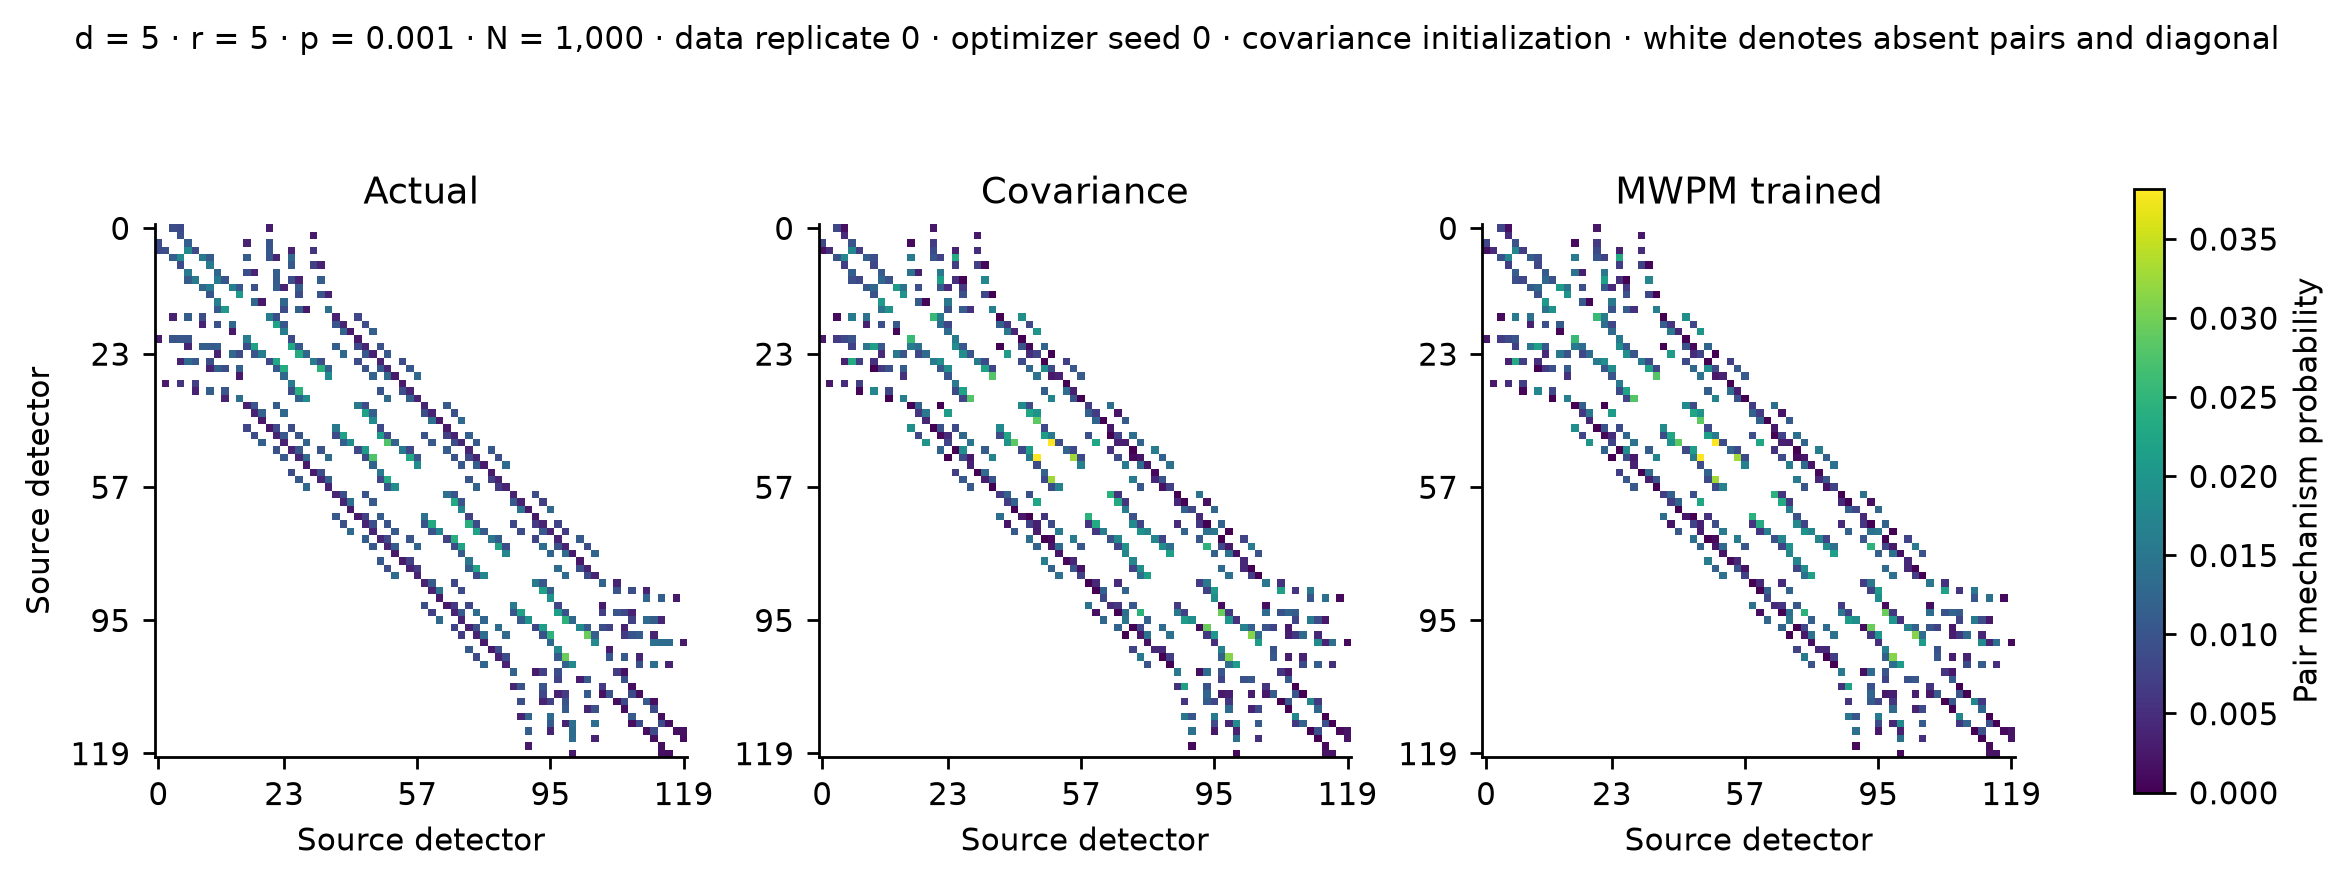

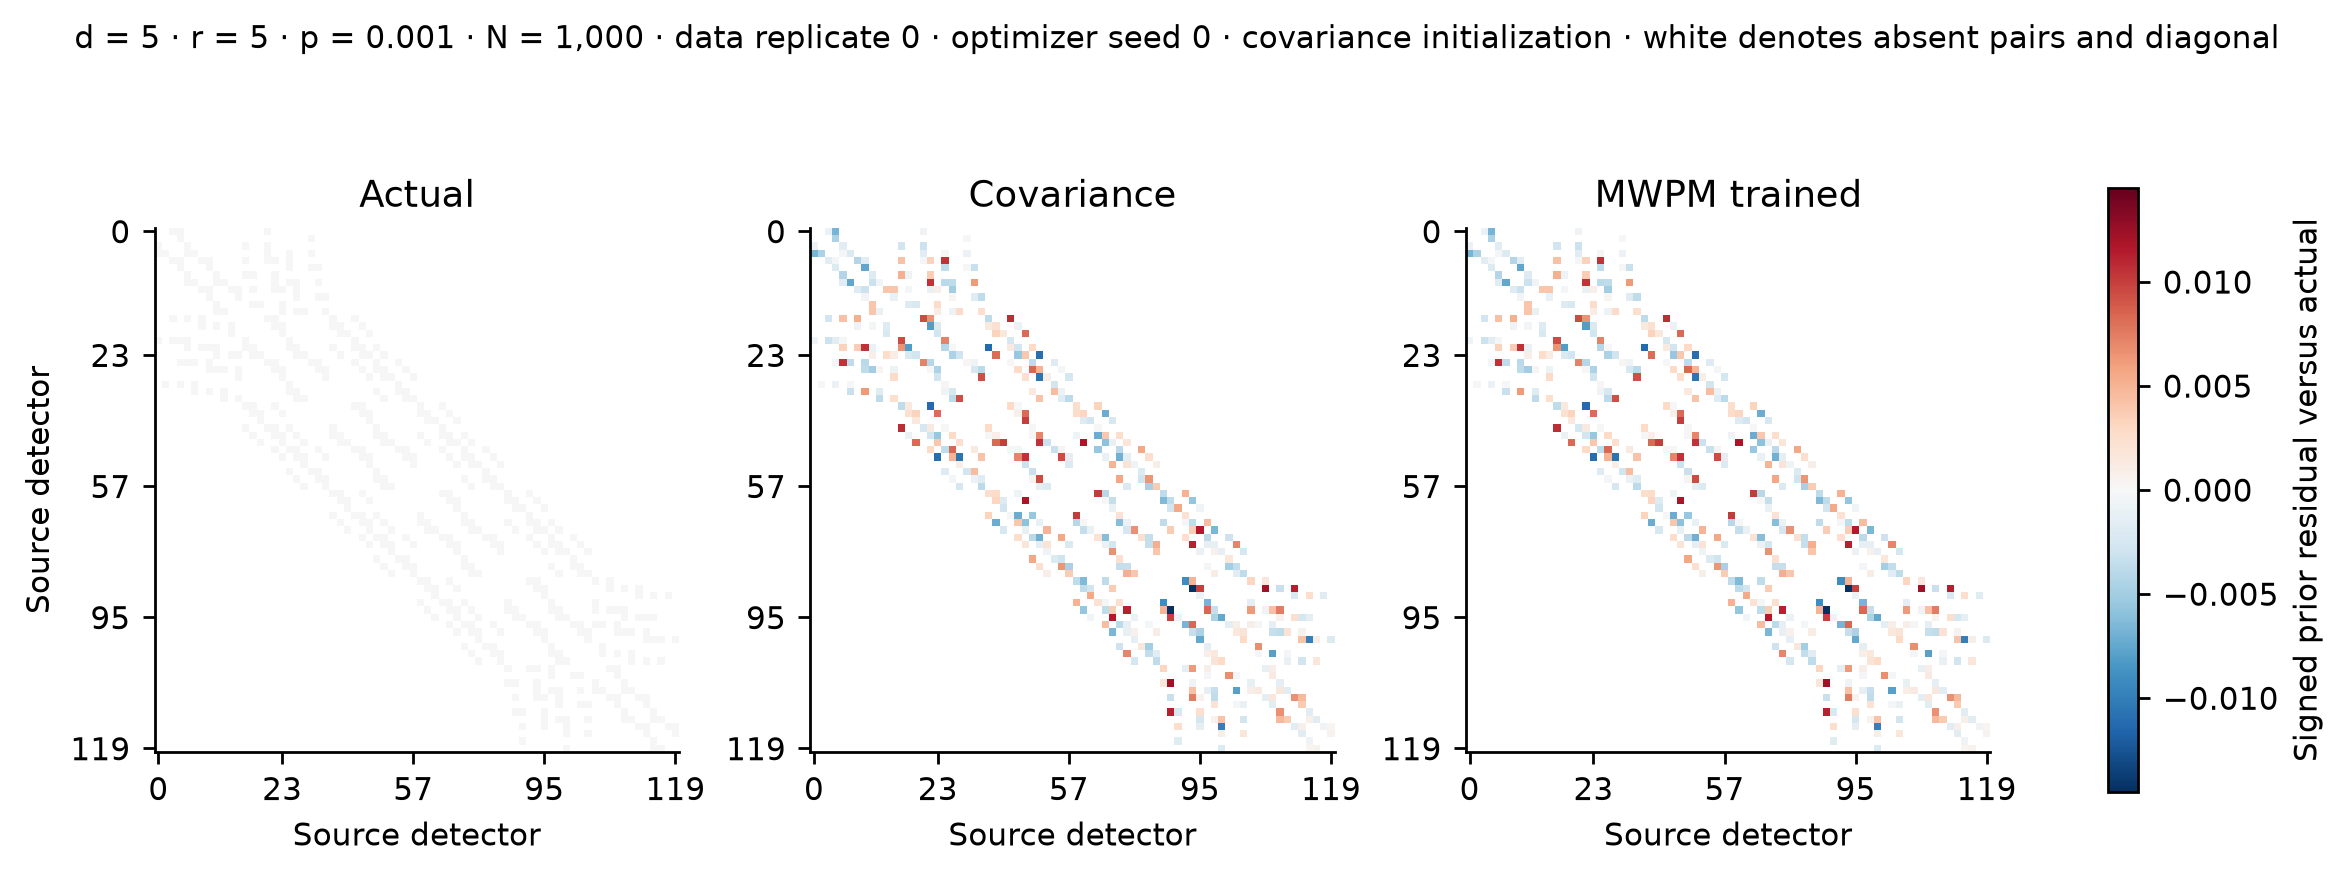

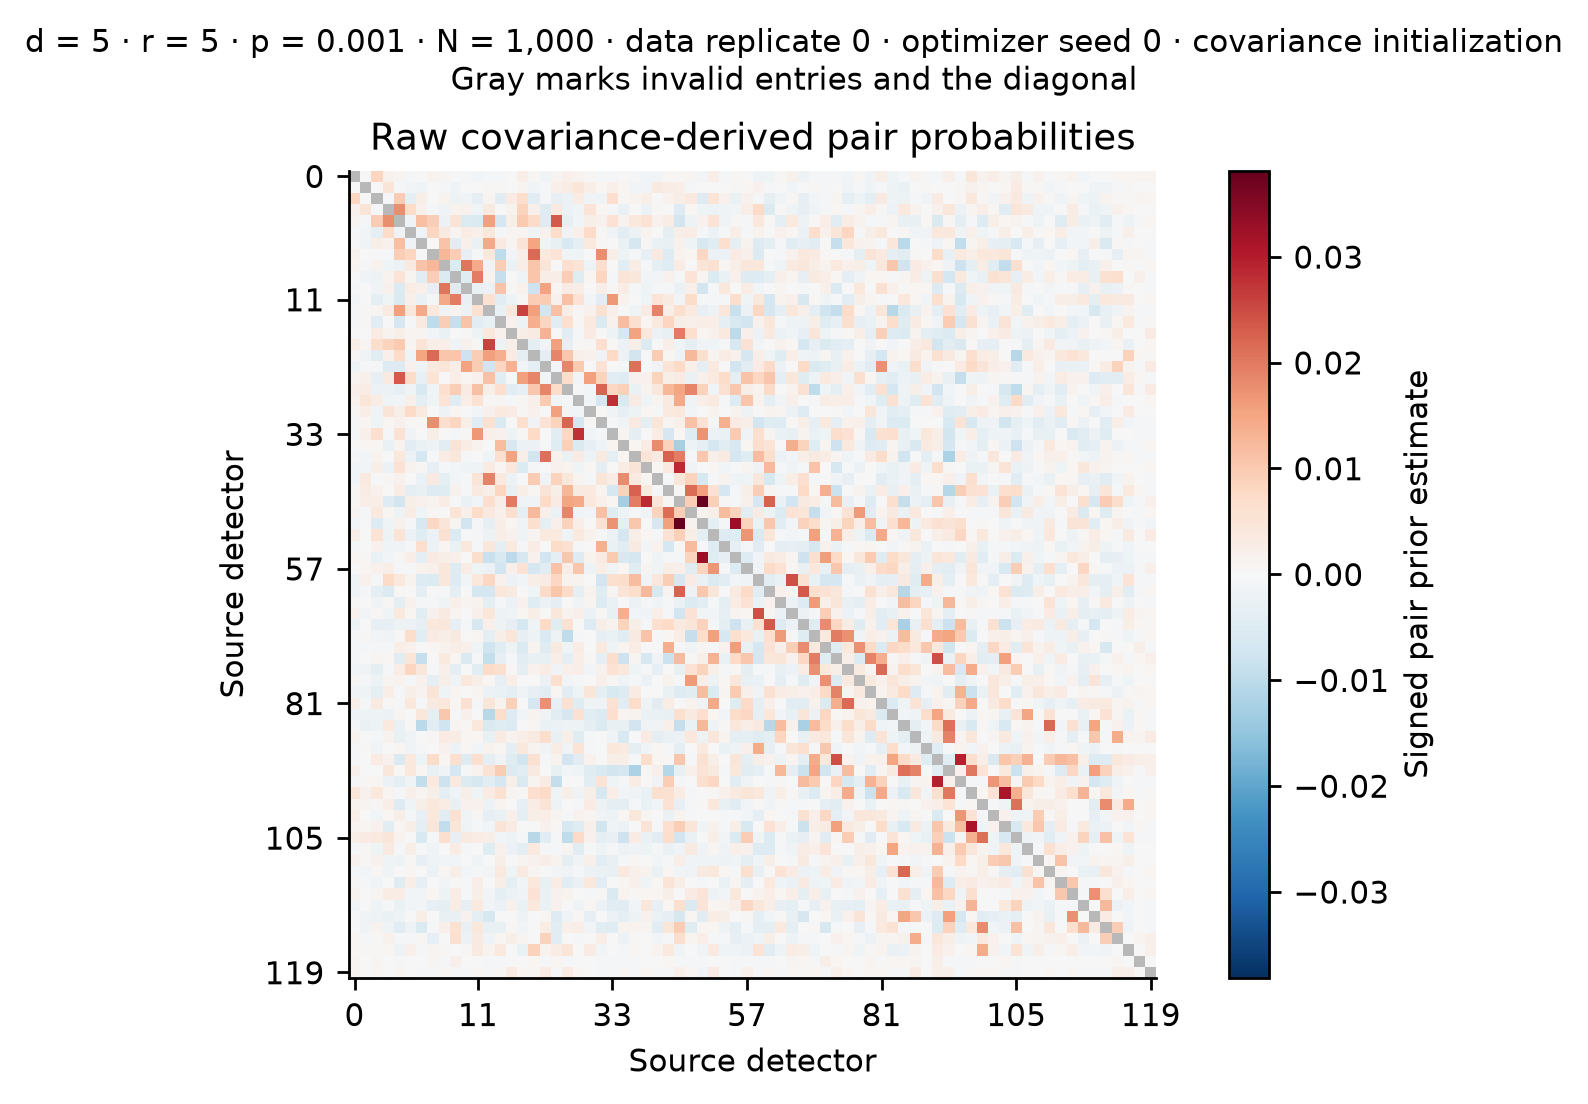

In [6]:
if "plot" in stages:
    figure_paths = plot_results(output, plot_options)
    display(Markdown(f"Generated {len(figure_paths)} figures from saved results in "
                     f"{figure_paths[0].parent}."))
    for path in figure_paths:
        if path.suffix == ".png" and path.stem in {
            "pair_priors", "pair_residuals_vs_actual", "raw_covariance_pair_priors",
            "cross_decoder_transfer", "failure_vs_physical_error", "failure_vs_calibration_shots",
        }:
            display(Image(filename=str(path)))